# 🩺 AI-Based Diabetic Retinopathy Detection & Monitoring

> **Capstone Project** | Transfer Learning (EfficientNet-B4) | APTOS 2019 Dataset

---

## 📋 Project Overview

**Task**: 5-class DR severity grading (ICDR scale):

| Grade | Label | Description |
|-------|-------|-------------|
| 0 | No DR | No apparent retinopathy |
| 1 | Mild | Microaneurysms only |
| 2 | Moderate | More than microaneurysms but less than severe NPDR |
| 3 | Severe | Severe NPDR — 4-2-1 rule |
| 4 | Proliferative DR | Neovascularization or vitreous/pre-retinal hemorrhage |

**Approach**: Transfer learning — EfficientNet-B4 (NoisyStudent) pretrained on ImageNet  
**Primary Metric**: Quadratic Weighted Kappa (QWK)  
**Dataset**: APTOS 2019 Blindness Detection (Kaggle, ~3,600 labelled fundus images)

---

## 🗺️ Notebook Structure

1. [Phase 1 — Setup & Data](#phase1)
2. [Phase 2 — Model Development](#phase2)
3. [Phase 3 — Evaluation & Grad-CAM](#phase3)
4. [Phase 4 — Monitoring Backend](#phase4)
5. [Summary](#summary)

---
# Phase 1: Environment Setup & Data
<a id='phase1'></a>

## 1.1 Install Dependencies

In [1]:
# Install required packages — restart Colab runtime after if prompted
!pip install -q \
    torch torchvision torchaudio \
    timm \
    opencv-python-headless \
    albumentations \
    scikit-learn \
    matplotlib seaborn \
    grad-cam \
    kaggle \
    tqdm \
    pandas numpy \
    Pillow

print("Dependencies installed")

You should consider upgrading via the '/Users/minitkumar/Desktop/Project- AI-Based Diabetic Retinopathy Detection & Monitoring/venv/bin/python3 -m pip install --upgrade pip' command.
Dependencies installed


## 1.2 Core Imports & Global Configuration

In [2]:
import os, sqlite3, random, warnings, json, datetime
from pathlib import Path
from collections import Counter
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2

from sklearn.model_selection import train_test_split
from sklearn.metrics import (cohen_kappa_score, confusion_matrix,
                              classification_report, roc_auc_score, roc_curve)
from sklearn.preprocessing import label_binarize

import matplotlib.pyplot as plt
import seaborn as sns

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

from tqdm.notebook import tqdm

# ── Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True

# ── Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"  GPU : {torch.cuda.get_device_name(0)}")
    print(f"  VRAM: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
else:
    print("  No GPU detected — use Colab T4 GPU for faster training.")

# ── Constants
CLASS_NAMES  = ["No DR", "Mild", "Moderate", "Severe", "Proliferative"]
NUM_CLASSES  = 5
IMG_SIZE     = 380
BATCH_SIZE   = 16
NUM_EPOCHS   = 20
LR_HEAD      = 1e-3
LR_FINETUNE  = 1e-4
WEIGHT_DECAY = 1e-4
PALETTE      = ["#2ecc71","#f1c40f","#e67e22","#e74c3c","#8e44ad"]

# ── Paths
BASE_DIR      = Path(".")
DATA_DIR      = BASE_DIR / "aptos2019-blindness-detection"
TRAIN_IMG_DIR = DATA_DIR / "train_images"
TEST_IMG_DIR  = DATA_DIR / "test_images"
CKPT_DIR      = BASE_DIR / "checkpoints"
LOG_DIR       = BASE_DIR / "logs"
DB_PATH       = BASE_DIR / "monitoring.db"

for d in [DATA_DIR, TRAIN_IMG_DIR, TEST_IMG_DIR, CKPT_DIR, LOG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("Directory structure ready")

Device: cpu
  No GPU detected — use Colab T4 GPU for faster training.
Directory structure ready


## 1.3 Download APTOS 2019 Dataset

> **Kaggle API setup**:
> 1. Go to [kaggle.com/account](https://www.kaggle.com/account) → *Create New API Token* → download `kaggle.json`
> 2. **Google Colab**: upload `kaggle.json` via the Files panel, then run the cell below.
> 3. **Local machine**: place `kaggle.json` at `~/.kaggle/kaggle.json`

In [ ]:
# Kaggle setup removed because we are using local data


In [3]:
train_csv = pd.read_csv(DATA_DIR / "train.csv")
print(f"Dataset shape: {train_csv.shape}")
display(train_csv.head())

Dataset shape: (3662, 2)


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0


## 1.4 Exploratory Data Analysis (EDA)

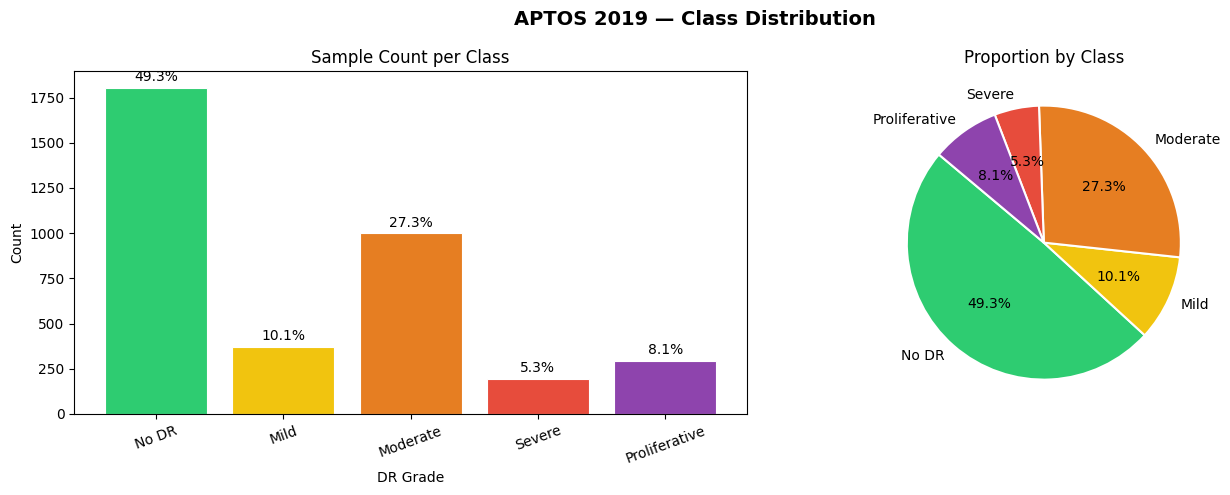


Class breakdown:
  Grade 0 (        No DR): 1805  ||||||||||||||||||||||||  49.3%
  Grade 1 (         Mild):  370  |||||  10.1%
  Grade 2 (     Moderate):  999  |||||||||||||  27.3%
  Grade 3 (       Severe):  193  ||  5.3%
  Grade 4 (Proliferative):  295  ||||  8.1%

  Total: 3662 images

  Class imbalance: No DR dominates ~49%. Addressed via Focal Loss + sampling.


In [4]:
label_col  = "diagnosis"
counts     = train_csv[label_col].value_counts().sort_index()
class_pcts = (counts / counts.sum() * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("APTOS 2019 — Class Distribution", fontsize=14, fontweight="bold")

bars = axes[0].bar(CLASS_NAMES, counts.values, color=PALETTE, edgecolor="white", lw=0.8)
for bar, pct in zip(bars, class_pcts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height()+20,
                 f"{pct}%", ha="center", va="bottom", fontsize=10)
axes[0].set_xlabel("DR Grade"); axes[0].set_ylabel("Count")
axes[0].set_title("Sample Count per Class")
axes[0].tick_params(axis="x", rotation=20)

axes[1].pie(counts.values, labels=CLASS_NAMES, colors=PALETTE,
            autopct="%1.1f%%", startangle=140,
            wedgeprops=dict(edgecolor="white", linewidth=1.5))
axes[1].set_title("Proportion by Class")

plt.tight_layout()
plt.savefig(LOG_DIR / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nClass breakdown:")
for i, (name, cnt, pct) in enumerate(zip(CLASS_NAMES, counts.values, class_pcts.values)):
    print(f"  Grade {i} ({name:>13s}): {cnt:4d}  {'|'*int(pct/2)}  {pct}%")
print(f"\n  Total: {counts.sum()} images")
print("\n  Class imbalance: No DR dominates ~49%. Addressed via Focal Loss + sampling.")

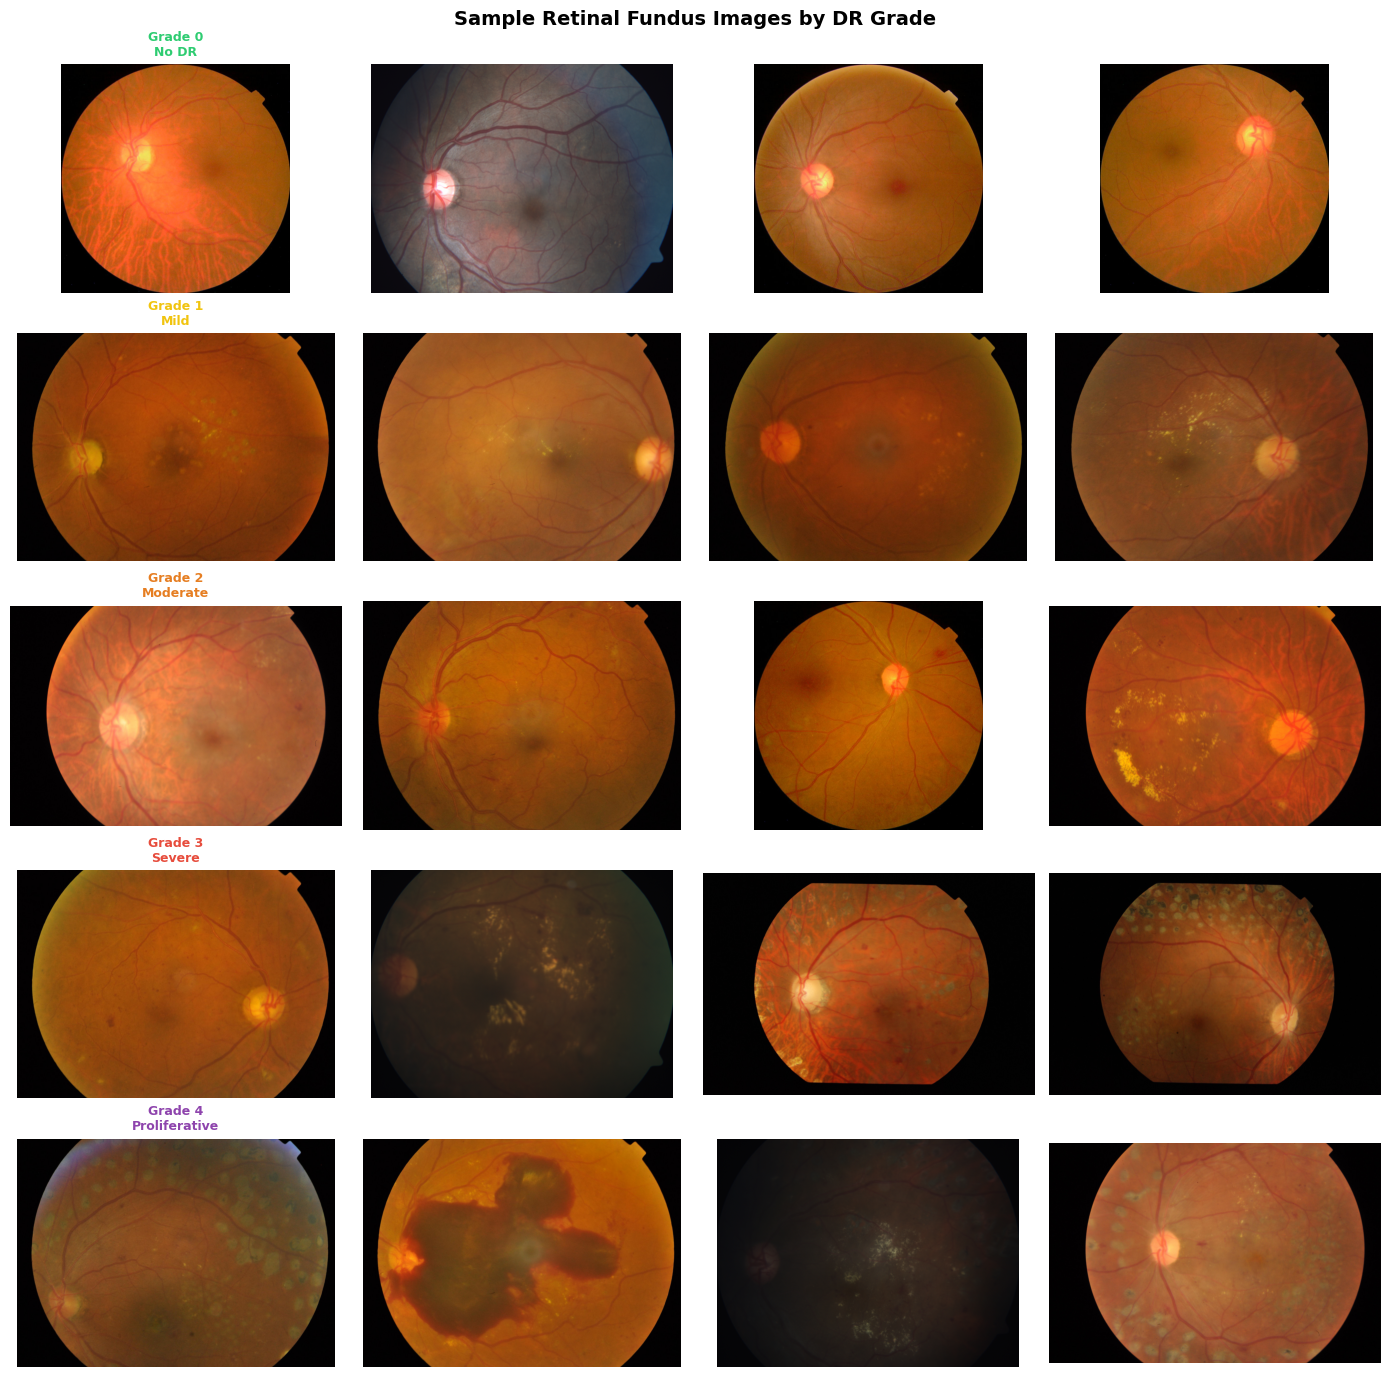

In [5]:
# Sample images per grade
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(14, 14))
fig.suptitle("Sample Retinal Fundus Images by DR Grade", fontsize=14, fontweight="bold")

for grade in range(NUM_CLASSES):
    subset  = train_csv[train_csv[label_col] == grade]
    samples = subset.sample(min(4, len(subset)), random_state=SEED)
    for col, (_, row) in enumerate(samples.iterrows()):
        img_path = TRAIN_IMG_DIR / f"{row['id_code']}.png"
        if img_path.exists():
            img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
            axes[grade][col].imshow(img)
        axes[grade][col].axis("off")
        if col == 0:
            axes[grade][col].set_title(
                f"Grade {grade}\n{CLASS_NAMES[grade]}",
                fontsize=9, fontweight="bold", color=PALETTE[grade])

plt.tight_layout()
plt.savefig(LOG_DIR / "sample_images.png", dpi=120, bbox_inches="tight")
plt.show()

## 1.5 Preprocessing Pipeline

Standard DR literature preprocessing:
1. **Crop black borders** — remove uninformative boundary pixels
2. **Ben Graham Gaussian subtraction** — normalise uneven fundus illumination
3. **Circular retinal disc mask** — focus on the fundus region
4. **CLAHE** — enhance local contrast (microaneurysms, haemorrhages become more visible)
5. **Resize** to 380×380 + **ImageNet normalisation**

Preprocessing functions ready


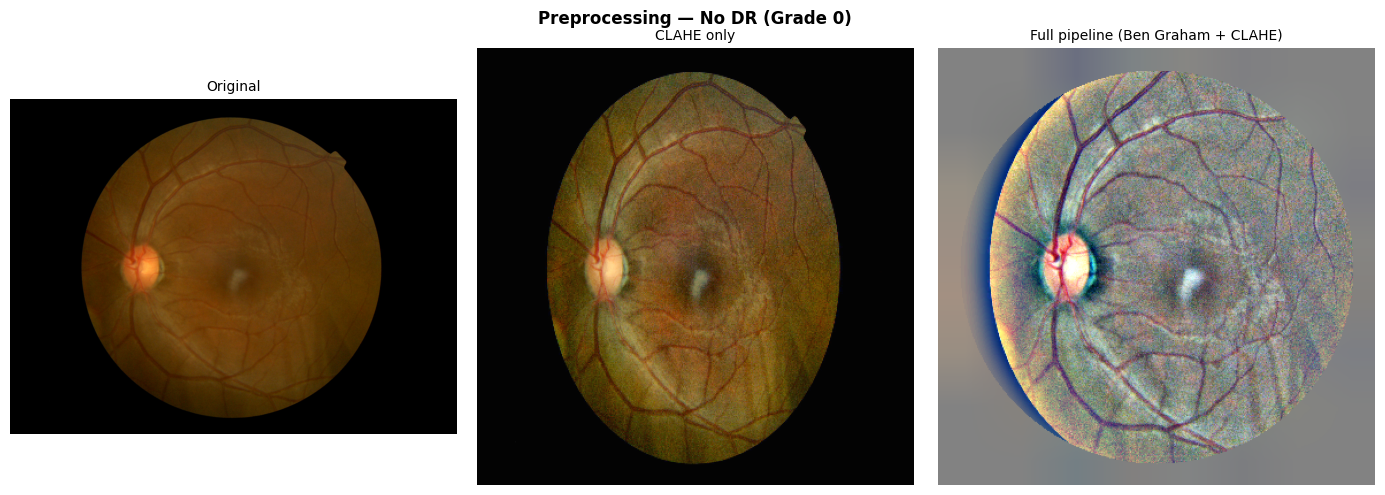

In [6]:
def crop_black_borders(img, tolerance=7):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    mask = gray > tolerance
    rows, cols = np.any(mask, axis=1), np.any(mask, axis=0)
    rmin, rmax = np.where(rows)[0][[0,-1]]
    cmin, cmax = np.where(cols)[0][[0,-1]]
    return img[rmin:rmax+1, cmin:cmax+1]


def apply_clahe(img, clip_limit=2.0, tile=8):
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(tile, tile))
    return cv2.merge([clahe.apply(ch) for ch in cv2.split(img)])


def ben_graham_preprocess(img, img_size):
    try:
        img = crop_black_borders(img)
    except (IndexError, ValueError):
        pass
    img     = cv2.resize(img, (img_size, img_size))
    blurred = cv2.GaussianBlur(img, (0,0), sigmaX=img_size/30)
    img     = cv2.addWeighted(img, 4, blurred, -4, 128)
    mask    = np.zeros_like(img)
    r       = img_size // 2
    cv2.circle(mask, (r, r), int(r * 0.9), (1,1,1), -1)
    img     = img * mask + 128 * (1 - mask)
    return img.astype(np.uint8)


def load_and_preprocess(path, img_size=IMG_SIZE, use_clahe=True):
    img = cv2.imread(str(path))
    if img is None:
        raise FileNotFoundError(f"Cannot read: {path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = ben_graham_preprocess(img, img_size)
    if use_clahe:
        img = apply_clahe(img)
    return img


print("Preprocessing functions ready")

# Visualise preprocessing effect
sample_row  = train_csv.sample(1, random_state=SEED).iloc[0]
sample_path = TRAIN_IMG_DIR / f"{sample_row['id_code']}.png"

if sample_path.exists():
    raw  = cv2.cvtColor(cv2.imread(str(sample_path)), cv2.COLOR_BGR2RGB)
    proc = load_and_preprocess(sample_path)
    clahe_only = cv2.resize(apply_clahe(raw), (IMG_SIZE, IMG_SIZE))

    fig, axes = plt.subplots(1, 3, figsize=(14, 5))
    fig.suptitle(
        f"Preprocessing — {CLASS_NAMES[sample_row['diagnosis']]} (Grade {sample_row['diagnosis']})",
        fontsize=12, fontweight="bold")
    for ax, img, title in zip(axes, [raw, clahe_only, proc],
                              ["Original", "CLAHE only", "Full pipeline (Ben Graham + CLAHE)"]):
        ax.imshow(img); ax.set_title(title, fontsize=10); ax.axis("off")
    plt.tight_layout()
    plt.savefig(LOG_DIR / "preprocessing_comparison.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Run after downloading the dataset to visualise preprocessing.")

## 1.6 Stratified 70 / 15 / 15 Train–Val–Test Split

In [7]:
df           = train_csv.copy()
df["filepath"] = df["id_code"].apply(lambda x: str(TRAIN_IMG_DIR / f"{x}.png"))
df["label"]    = df[label_col].astype(int)

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

print(f"{'Split':<12} {'Samples':>8}   Grade distribution (0 → 4)")
print("-" * 65)
for name, split in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    dist = split["label"].value_counts(normalize=True).sort_index().apply(lambda x: f"{x:.1%}")
    print(f"{name:<12} {len(split):>8}   {' | '.join(dist.values)}")

train_df.to_csv(LOG_DIR / "train_split.csv", index=False)
val_df.to_csv(LOG_DIR / "val_split.csv",     index=False)
test_df.to_csv(LOG_DIR / "test_split.csv",   index=False)
print("\nSplits saved to logs/")

Split         Samples   Grade distribution (0 → 4)
-----------------------------------------------------------------
Train            2563   49.3% | 10.1% | 27.3% | 5.3% | 8.1%
Validation        549   49.4% | 10.0% | 27.3% | 5.3% | 8.0%
Test              550   49.3% | 10.2% | 27.3% | 5.3% | 8.0%

Splits saved to logs/


## 1.7 PyTorch Dataset & DataLoaders

In [16]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transforms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=30, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=20, p=0.3),
    A.GaussNoise(var_limit=(5.0, 30.0), p=0.2),
    A.CoarseDropout(max_holes=8, max_height=32, max_width=32, p=0.2),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

val_transforms = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])


class DRDataset(Dataset):
    def __init__(self, df, transform=None, preprocess=True):
        self.df        = df.reset_index(drop=True)
        self.transform = transform
        self.preprocess = preprocess

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        label = int(row["label"])
        path  = row["filepath"]
        if self.preprocess:
            img = load_and_preprocess(path)
        else:
            img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        if self.transform:
            img = self.transform(image=img)["image"]
        return img, label


def make_weighted_sampler(labels):
    class_counts   = Counter(labels)
    total          = len(labels)
    class_weight   = {cls: total / cnt for cls, cnt in class_counts.items()}
    sample_weights = [class_weight[lbl] for lbl in labels]
    return WeightedRandomSampler(weights=sample_weights, num_samples=total, replacement=True)


train_dataset = DRDataset(train_df, transform=train_transforms)
val_dataset   = DRDataset(val_df,   transform=val_transforms)
test_dataset  = DRDataset(test_df,  transform=val_transforms)

train_sampler = make_weighted_sampler(train_df["label"].tolist())

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=train_sampler,
                          num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=0, pin_memory=True)

print("Datasets & DataLoaders ready")
print(f"  Train:      {len(train_dataset):>5} samples | {len(train_loader)} batches")
print(f"  Validation: {len(val_dataset):>5} samples | {len(val_loader)} batches")
print(f"  Test:       {len(test_dataset):>5} samples | {len(test_loader)} batches")

Datasets & DataLoaders ready
  Train:       2563 samples | 161 batches
  Validation:   549 samples | 35 batches
  Test:         550 samples | 35 batches


---
# Phase 2: Model Development
<a id='phase2'></a>

## 2.1 Model Architecture — EfficientNet-B4 (Transfer Learning)

**Why EfficientNet-B4?**
- Best accuracy/parameter trade-off across medical imaging benchmarks
- Native 380×380 input resolution captures fine retinal features (microaneurysms ~50µm)
- NoisyStudent pre-training (self-supervised) provides stronger generalisation than standard ImageNet weights

**Two-phase fine-tuning**:
1. **Phase A** (5 epochs) — Backbone frozen, train classifier head only → fast convergence
2. **Phase B** (15 epochs) — Unfreeze all layers, differential LR (backbone 10× lower than head)

In [17]:
class DRClassifier(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, dropout_p=0.4, pretrained=True):
        super().__init__()
        self.backbone = timm.create_model(
            "tf_efficientnet_b4_ns",
            pretrained=pretrained,
            num_classes=0,
            global_pool="avg",
        )
        feat_dim = self.backbone.num_features  # 1792 for B4
        self.classifier = nn.Sequential(
            nn.Dropout(p=dropout_p),
            nn.Linear(feat_dim, 512),
            nn.GELU(),
            nn.BatchNorm1d(512),
            nn.Dropout(p=dropout_p / 2),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.backbone(x))

    def freeze_backbone(self):
        for p in self.backbone.parameters(): p.requires_grad = False
        print("Backbone FROZEN — training head only")

    def unfreeze_backbone(self):
        for p in self.backbone.parameters(): p.requires_grad = True
        print("Backbone UNFROZEN — end-to-end fine-tuning")

    def count_parameters(self):
        total     = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        print(f"  Total:     {total:>12,}")
        print(f"  Trainable: {trainable:>12,}")
        print(f"  Frozen:    {total - trainable:>12,}")


model = DRClassifier(pretrained=True).to(DEVICE)
model.freeze_backbone()
print("\nParameter count (Phase A — head only):")
model.count_parameters()

Backbone FROZEN — training head only

Parameter count (Phase A — head only):
  Total:       18,470,221
  Trainable:      921,605
  Frozen:      17,548,616


## 2.2 Focal Loss + Inverse-Frequency Class Weights

- **Focal Loss** (γ=2): down-weights easy majority-class examples, focuses gradient on hard minority samples
- **Class weights**: inverse frequency weighting ensures rare grades (Severe, Proliferative) are prioritised
- Combined effect is significantly better than standard CrossEntropy for imbalanced datasets

In [18]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0, reduction="mean"):
        super().__init__()
        self.alpha = alpha; self.gamma = gamma; self.reduction = reduction

    def forward(self, inputs, targets):
        ce   = F.cross_entropy(inputs, targets, weight=self.alpha, reduction="none")
        pt   = torch.exp(-ce)
        loss = ((1 - pt) ** self.gamma) * ce
        return loss.mean() if self.reduction == "mean" else loss.sum()


label_counts  = np.bincount(train_df["label"].values, minlength=NUM_CLASSES)
class_weights = 1.0 / (label_counts / label_counts.sum())
class_weights /= class_weights.sum() / NUM_CLASSES
class_weights  = torch.FloatTensor(class_weights).to(DEVICE)

print("Class weights (inverse frequency):")
for i, (name, w) in enumerate(zip(CLASS_NAMES, class_weights.cpu())):
    print(f"  Grade {i} ({name:>13s}): {w:.3f}")

criterion = FocalLoss(alpha=class_weights, gamma=2.0)
print("\nFocal Loss ready")

Class weights (inverse frequency):
  Grade 0 (        No DR): 0.216
  Grade 1 (         Mild): 1.054
  Grade 2 (     Moderate): 0.390
  Grade 3 (       Severe): 2.021
  Grade 4 (Proliferative): 1.318

Focal Loss ready


## 2.3 Training Utilities

In [19]:
def train_one_epoch(model, loader, optimizer, scheduler, criterion, scaler):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels      = [], []

    for imgs, labels in tqdm(loader, desc="  Train", leave=False):
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
            logits = model(imgs)
            loss   = criterion(logits, labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update()

        total_loss += loss.item() * imgs.size(0)
        preds       = logits.argmax(1)
        correct    += (preds == labels).sum().item()
        total      += imgs.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    if scheduler: scheduler.step()
    return (total_loss / total,
            correct / total,
            cohen_kappa_score(all_labels, all_preds, weights="quadratic"))


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels, all_probs = [], [], []

    for imgs, labels in tqdm(loader, desc="  Val  ", leave=False):
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
            logits = model(imgs)
            loss   = criterion(logits, labels)
        total_loss += loss.item() * imgs.size(0)
        probs       = torch.softmax(logits, 1)
        preds       = probs.argmax(1)
        correct    += (preds == labels).sum().item()
        total      += imgs.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

    return (total_loss / total,
            correct / total,
            cohen_kappa_score(all_labels, all_preds, weights="quadratic"),
            all_preds, all_labels, all_probs)


class EarlyStopping:
    def __init__(self, patience=5, mode="max", delta=1e-4):
        self.patience = patience; self.mode = mode; self.delta = delta
        self.best = None; self.counter = 0; self.stop = False

    def __call__(self, score):
        if self.best is None:
            self.best = score
        elif (self.mode == "max" and score < self.best + self.delta) or              (self.mode == "min" and score > self.best - self.delta):
            self.counter += 1
            if self.counter >= self.patience: self.stop = True
        else:
            self.best = score; self.counter = 0
        return self.stop


def save_ckpt(model, opt, epoch, kappa, path):
    torch.save({"epoch": epoch, "model_state_dict": model.state_dict(),
                "optimizer_state_dict": opt.state_dict(), "kappa": kappa}, path)


BEST_CKPT = CKPT_DIR / "best_model.pth"
print("Training utilities ready")

Training utilities ready


## 2.4 Phase A — Train Classifier Head Only

In [ ]:
PHASE_A_EPOCHS = 5

model.freeze_backbone()
optimizer  = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                                lr=LR_HEAD, weight_decay=WEIGHT_DECAY)
scheduler  = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=PHASE_A_EPOCHS, eta_min=1e-6)
scaler     = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))
early_stop = EarlyStopping(patience=3, mode="max")
history    = {k: [] for k in ["train_loss","val_loss","train_kappa","val_kappa","train_acc","val_acc","lr"]}
best_kappa = 0.0

print("Phase A — classifier head only (backbone frozen)")
print("=" * 70)

for epoch in range(1, PHASE_A_EPOCHS + 1):
    lr_now      = optimizer.param_groups[0]["lr"]
    tl, ta, tk  = train_one_epoch(model, train_loader, optimizer, scheduler, criterion, scaler)
    vl, va, vk, _, _, _ = evaluate(model, val_loader, criterion)

    for key, val in zip(["train_loss","val_loss","train_kappa","val_kappa","train_acc","val_acc","lr"],
                        [tl, vl, tk, vk, ta, va, lr_now]):
        history[key].append(val)

    star = ""
    if vk > best_kappa:
        best_kappa = vk
        save_ckpt(model, optimizer, epoch, vk, BEST_CKPT)
        star = "  ** Best **"

    print(f"  E{epoch:02d} | Train  loss:{tl:.4f}  kappa:{tk:.4f} | "
          f"Val  loss:{vl:.4f}  kappa:{vk:.4f}{star}")
    if early_stop(vk): print("  Early stopping triggered"); break

print(f"\nPhase A complete. Best Val QWK: {best_kappa:.4f}")

Backbone FROZEN — training head only
Phase A — classifier head only (backbone frozen)


  Train:   0%|          | 0/161 [00:00<?, ?it/s]

In [22]:
# Load the saved progress
checkpoint_path = CKPT_DIR / "phase1_complete.pth"

checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])

print("Model weights loaded successfully! Ready to continue.")


Model weights loaded successfully! Ready to continue.


## 2.5 Phase B — Full End-to-End Fine-Tuning

In [26]:
PHASE_B_EPOCHS = 10

ckpt = torch.load(BEST_CKPT, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt["model_state_dict"])
model.unfreeze_backbone()

optimizer = torch.optim.AdamW([
    {"params": model.backbone.parameters(),   "lr": LR_FINETUNE},
    {"params": model.classifier.parameters(), "lr": LR_HEAD},
], weight_decay=WEIGHT_DECAY)
scheduler  = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=5, T_mult=2, eta_min=1e-7)
scaler     = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))
early_stop = EarlyStopping(patience=5, mode="max")

print("Phase B — full end-to-end fine-tuning")
print("=" * 70)

for epoch in range(1, PHASE_B_EPOCHS + 1):
    lr_now      = optimizer.param_groups[0]["lr"]
    tl, ta, tk  = train_one_epoch(model, train_loader, optimizer, scheduler, criterion, scaler)
    vl, va, vk, _, _, _ = evaluate(model, val_loader, criterion)

    for key, val in zip(["train_loss","val_loss","train_kappa","val_kappa","train_acc","val_acc","lr"],
                        [tl, vl, tk, vk, ta, va, lr_now]):
        history[key].append(val)

    star = ""
    if vk > best_kappa:
        best_kappa = vk
        save_ckpt(model, optimizer, epoch, vk, BEST_CKPT)
        star = "  ** Best **"

    print(f"  E{epoch:02d} | Train  loss:{tl:.4f}  kappa:{tk:.4f} | "
          f"Val  loss:{vl:.4f}  kappa:{vk:.4f}{star}")
    if early_stop(vk): print("  Early stopping triggered"); break

print(f"\nPhase B complete. Best Val QWK: {best_kappa:.4f}")

Backbone UNFROZEN — end-to-end fine-tuning
Phase B — full end-to-end fine-tuning


  Train:   0%|          | 0/161 [00:00<?, ?it/s]

  Val  :   0%|          | 0/35 [00:00<?, ?it/s]

  E01 | Train  loss:0.6329  kappa:0.5571 | Val  loss:0.3035  kappa:0.6665  ** Best **


  Train:   0%|          | 0/161 [00:00<?, ?it/s]

...

  Train:   0%|          | 0/161 [00:00<?, ?it/s]

  Val  :   0%|          | 0/35 [00:00<?, ?it/s]

  E04 | Train  loss:0.3085  kappa:0.7511 | Val  loss:0.2424  kappa:0.7007  ** Best **


  Train:   0%|          | 0/161 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [29]:
torch.save({'model_state_dict': model.state_dict(),}, CKPT_DIR / "model_epoch_3.pth")

print("Saved!")



Saved!


## 2.6 Training Curves

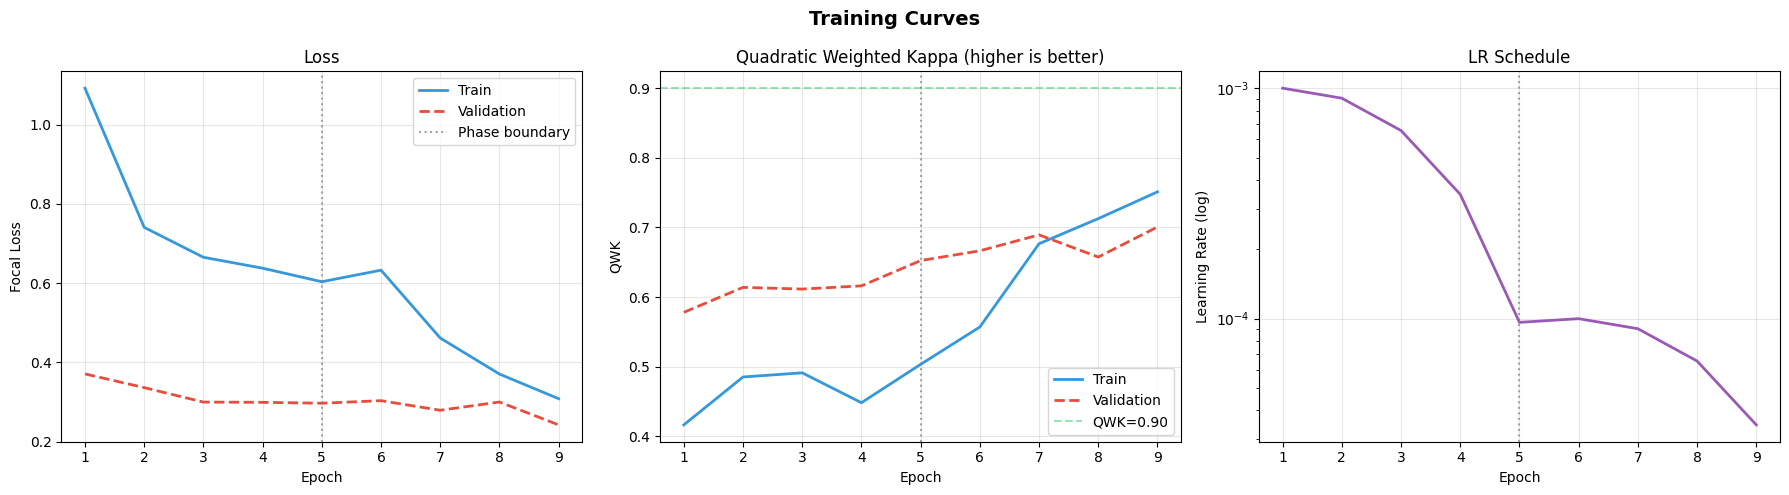

Training curves saved


In [30]:
n = len(history["train_loss"])
x = range(1, n + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Training Curves", fontsize=14, fontweight="bold")

axes[0].plot(x, history["train_loss"], label="Train",      color="#3498db", lw=2)
axes[0].plot(x, history["val_loss"],   label="Validation", color="#e74c3c", lw=2, ls="--")
axes[0].axvline(PHASE_A_EPOCHS, color="grey", ls=":", alpha=0.7, label="Phase boundary")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Focal Loss")
axes[0].set_title("Loss"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(x, history["train_kappa"], label="Train",      color="#3498db", lw=2)
axes[1].plot(x, history["val_kappa"],   label="Validation", color="#e74c3c", lw=2, ls="--")
axes[1].axhline(0.9, color="#2ecc71", ls="--", alpha=0.5, label="QWK=0.90")
axes[1].axvline(PHASE_A_EPOCHS, color="grey", ls=":", alpha=0.7)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("QWK")
axes[1].set_title("Quadratic Weighted Kappa (higher is better)")
axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].semilogy(x, history["lr"], color="#9b59b6", lw=2)
axes[2].axvline(PHASE_A_EPOCHS, color="grey", ls=":", alpha=0.7)
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Learning Rate (log)")
axes[2].set_title("LR Schedule"); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(LOG_DIR / "training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame(history).to_csv(LOG_DIR / "training_history.csv", index=False)
print("Training curves saved")

---
# Phase 3: Evaluation & Explainability
<a id='phase3'></a>

## 3.1 Test Set Evaluation

In [31]:
ckpt = torch.load(BEST_CKPT, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt["model_state_dict"])
print(f"Loaded best checkpoint (epoch {ckpt['epoch']}, val QWK = {ckpt['kappa']:.4f})")

_, test_acc, test_kappa, test_preds, test_labels, test_probs = evaluate(model, test_loader, criterion)

kappa_interp = ("Almost perfect" if test_kappa > 0.80 else
                "Substantial"    if test_kappa > 0.60 else
                "Moderate"       if test_kappa > 0.40 else
                "Fair"           if test_kappa > 0.20 else "Poor")

print("\n" + "="*55)
print("  TEST SET RESULTS")
print("="*55)
print(f"  Accuracy             : {test_acc:.4f}  ({test_acc*100:.1f}%)")
print(f"  Quadratic Weighted κ : {test_kappa:.4f}  ({kappa_interp} agreement)")
print("="*55)

Loaded best checkpoint (epoch 4, val QWK = 0.7007)


  Val  :   0%|          | 0/35 [00:00<?, ?it/s]


  TEST SET RESULTS
  Accuracy             : 0.5564  (55.6%)
  Quadratic Weighted κ : 0.7549  (Substantial agreement)


## 3.2 Confusion Matrix

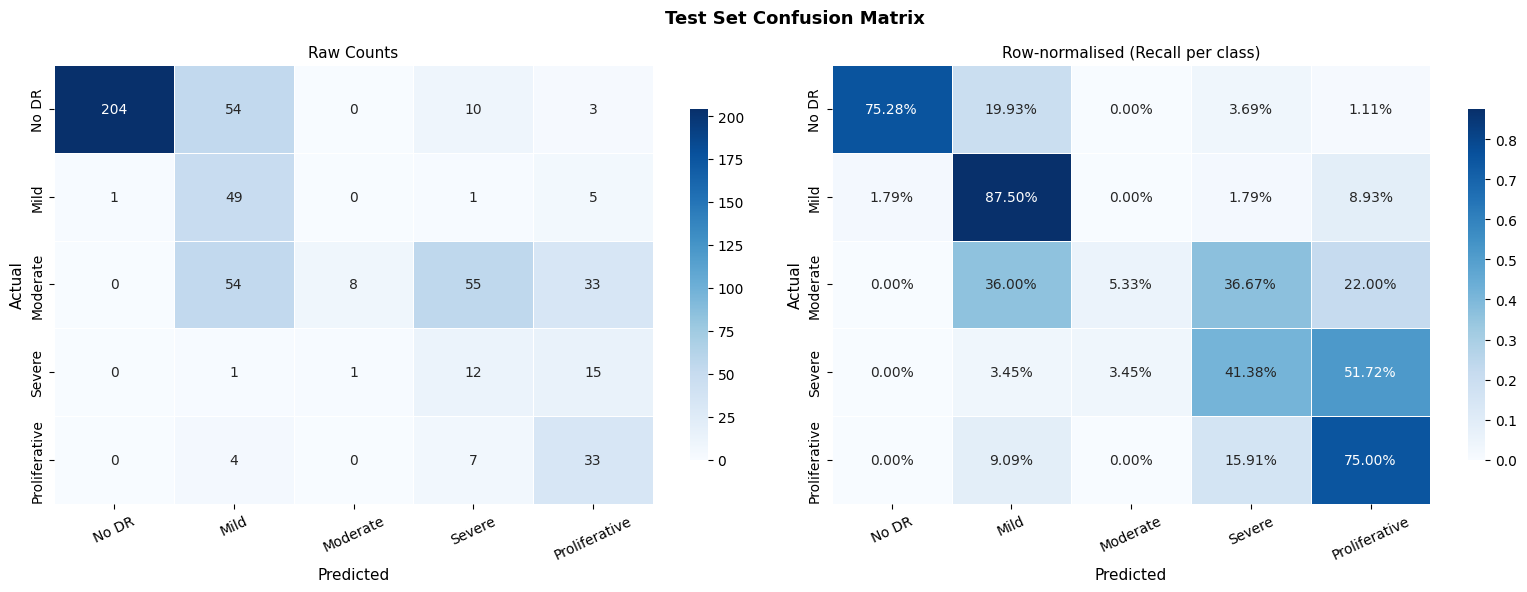

In [32]:
cm      = confusion_matrix(test_labels, test_preds, labels=list(range(NUM_CLASSES)))
cm_norm = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Test Set Confusion Matrix", fontsize=13, fontweight="bold")

for ax, data, fmt, title in zip(
    axes, [cm, cm_norm], ["d", ".2%"],
    ["Raw Counts", "Row-normalised (Recall per class)"]
):
    sns.heatmap(data, annot=True, fmt=fmt, cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                linewidths=0.5, linecolor="white", ax=ax, cbar_kws={"shrink":0.8})
    ax.set_xlabel("Predicted", fontsize=11)
    ax.set_ylabel("Actual", fontsize=11)
    ax.set_title(title, fontsize=11)
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.savefig(LOG_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## 3.3 Per-Class Sensitivity, Specificity & AUC

In [33]:
report    = classification_report(test_labels, test_preds, target_names=CLASS_NAMES, output_dict=True)
report_df = pd.DataFrame(report).T
print("Classification Report:")
display(report_df.style.format("{:.3f}", na_rep="-"))

test_probs_arr  = np.array(test_probs)
test_labels_bin = label_binarize(test_labels, classes=list(range(NUM_CLASSES)))

print("\nPer-class AUC (one-vs-rest):")
auc_scores = []
for i, name in enumerate(CLASS_NAMES):
    try:
        auc = roc_auc_score(test_labels_bin[:, i], test_probs_arr[:, i])
        auc_scores.append(auc)
        print(f"  Grade {i} ({name:>13s}): AUC = {auc:.4f}")
    except ValueError:
        auc_scores.append(float("nan"))
        print(f"  Grade {i} ({name:>13s}): AUC = N/A")

macro_auc = float(np.nanmean(auc_scores))
print(f"\n  Macro-average AUC: {macro_auc:.4f}")

metrics_summary = {"test_accuracy": test_acc, "test_qwk": test_kappa, "macro_auc": macro_auc,
                   "per_class_auc": dict(zip(CLASS_NAMES, [float(a) for a in auc_scores]))}
with open(LOG_DIR / "metrics_summary.json", "w") as f:
    json.dump(metrics_summary, f, indent=2)
print("Metrics saved to logs/metrics_summary.json")

Classification Report:


,precision,recall,f1-score,support
No DR,0.995,0.753,0.857,271.000
Mild,0.302,0.875,0.450,56.000
Moderate,0.889,0.053,0.101,150.000
Severe,0.141,0.414,0.211,29.000
Proliferative,0.371,0.750,0.496,44.000
accuracy,0.556,0.556,0.556,0.556
macro avg,0.540,0.569,0.423,550.000
weighted avg,0.801,0.556,0.546,550.000



Per-class AUC (one-vs-rest):
  Grade 0 (        No DR): AUC = 0.9913
  Grade 1 (         Mild): AUC = 0.8822
  Grade 2 (     Moderate): AUC = 0.9103
  Grade 3 (       Severe): AUC = 0.8134
  Grade 4 (Proliferative): AUC = 0.9064

  Macro-average AUC: 0.9007
Metrics saved to logs/metrics_summary.json


## 3.4 ROC Curves

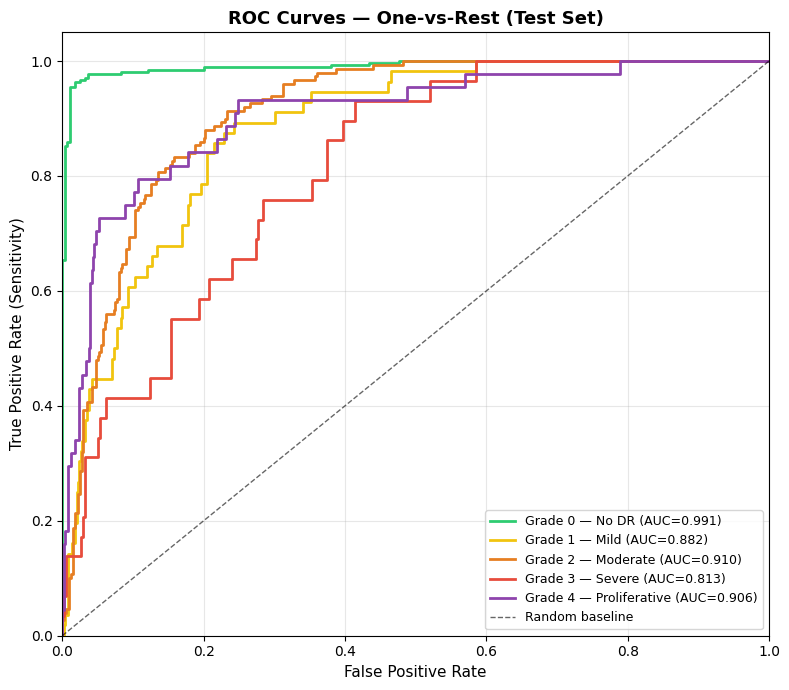

In [34]:
fig, ax = plt.subplots(figsize=(8, 7))

for i, (name, color) in enumerate(zip(CLASS_NAMES, PALETTE)):
    try:
        fpr, tpr, _ = roc_curve(test_labels_bin[:, i], test_probs_arr[:, i])
        ax.plot(fpr, tpr, color=color, lw=2,
                label=f"Grade {i} — {name} (AUC={auc_scores[i]:.3f})")
    except ValueError:
        pass

ax.plot([0,1],[0,1],"k--", lw=1, alpha=0.6, label="Random baseline")
ax.set_xlabel("False Positive Rate", fontsize=11)
ax.set_ylabel("True Positive Rate (Sensitivity)", fontsize=11)
ax.set_title("ROC Curves — One-vs-Rest (Test Set)", fontsize=13, fontweight="bold")
ax.legend(fontsize=9, loc="lower right"); ax.grid(alpha=0.3)
ax.set_xlim([0,1]); ax.set_ylim([0,1.05])

plt.tight_layout()
plt.savefig(LOG_DIR / "roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 3.5 Grad-CAM Explainability

Grad-CAM visualises *which retinal regions drove each prediction*.

**Clinical relevance**:
- Verify the model attends to actual pathological structures (microaneurysms, haemorrhages, neovascularisation)
- Detect dataset shortcut learning (e.g., camera artifacts)
- Standard expectation in medical AI papers — adds significant credibility

In [35]:
def get_target_layer(model):
    return [model.backbone.blocks[-1]]


def generate_gradcam(model, image_path, target_class=None):
    img_arr   = load_and_preprocess(image_path)
    img_float = img_arr.astype(np.float32) / 255.0
    tensor    = val_transforms(image=img_arr)["image"].unsqueeze(0).to(DEVICE)

    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(tensor), 1).squeeze().cpu().numpy()
    pred  = int(probs.argmax())
    tgt   = target_class if target_class is not None else pred

    cam     = GradCAM(model=model, target_layers=get_target_layer(model))
    cam_map = cam(input_tensor=tensor, targets=[ClassifierOutputTarget(tgt)])[0]
    overlay = show_cam_on_image(img_float, cam_map, use_rgb=True)
    return overlay, pred, probs


print("Grad-CAM utilities ready")

Grad-CAM utilities ready


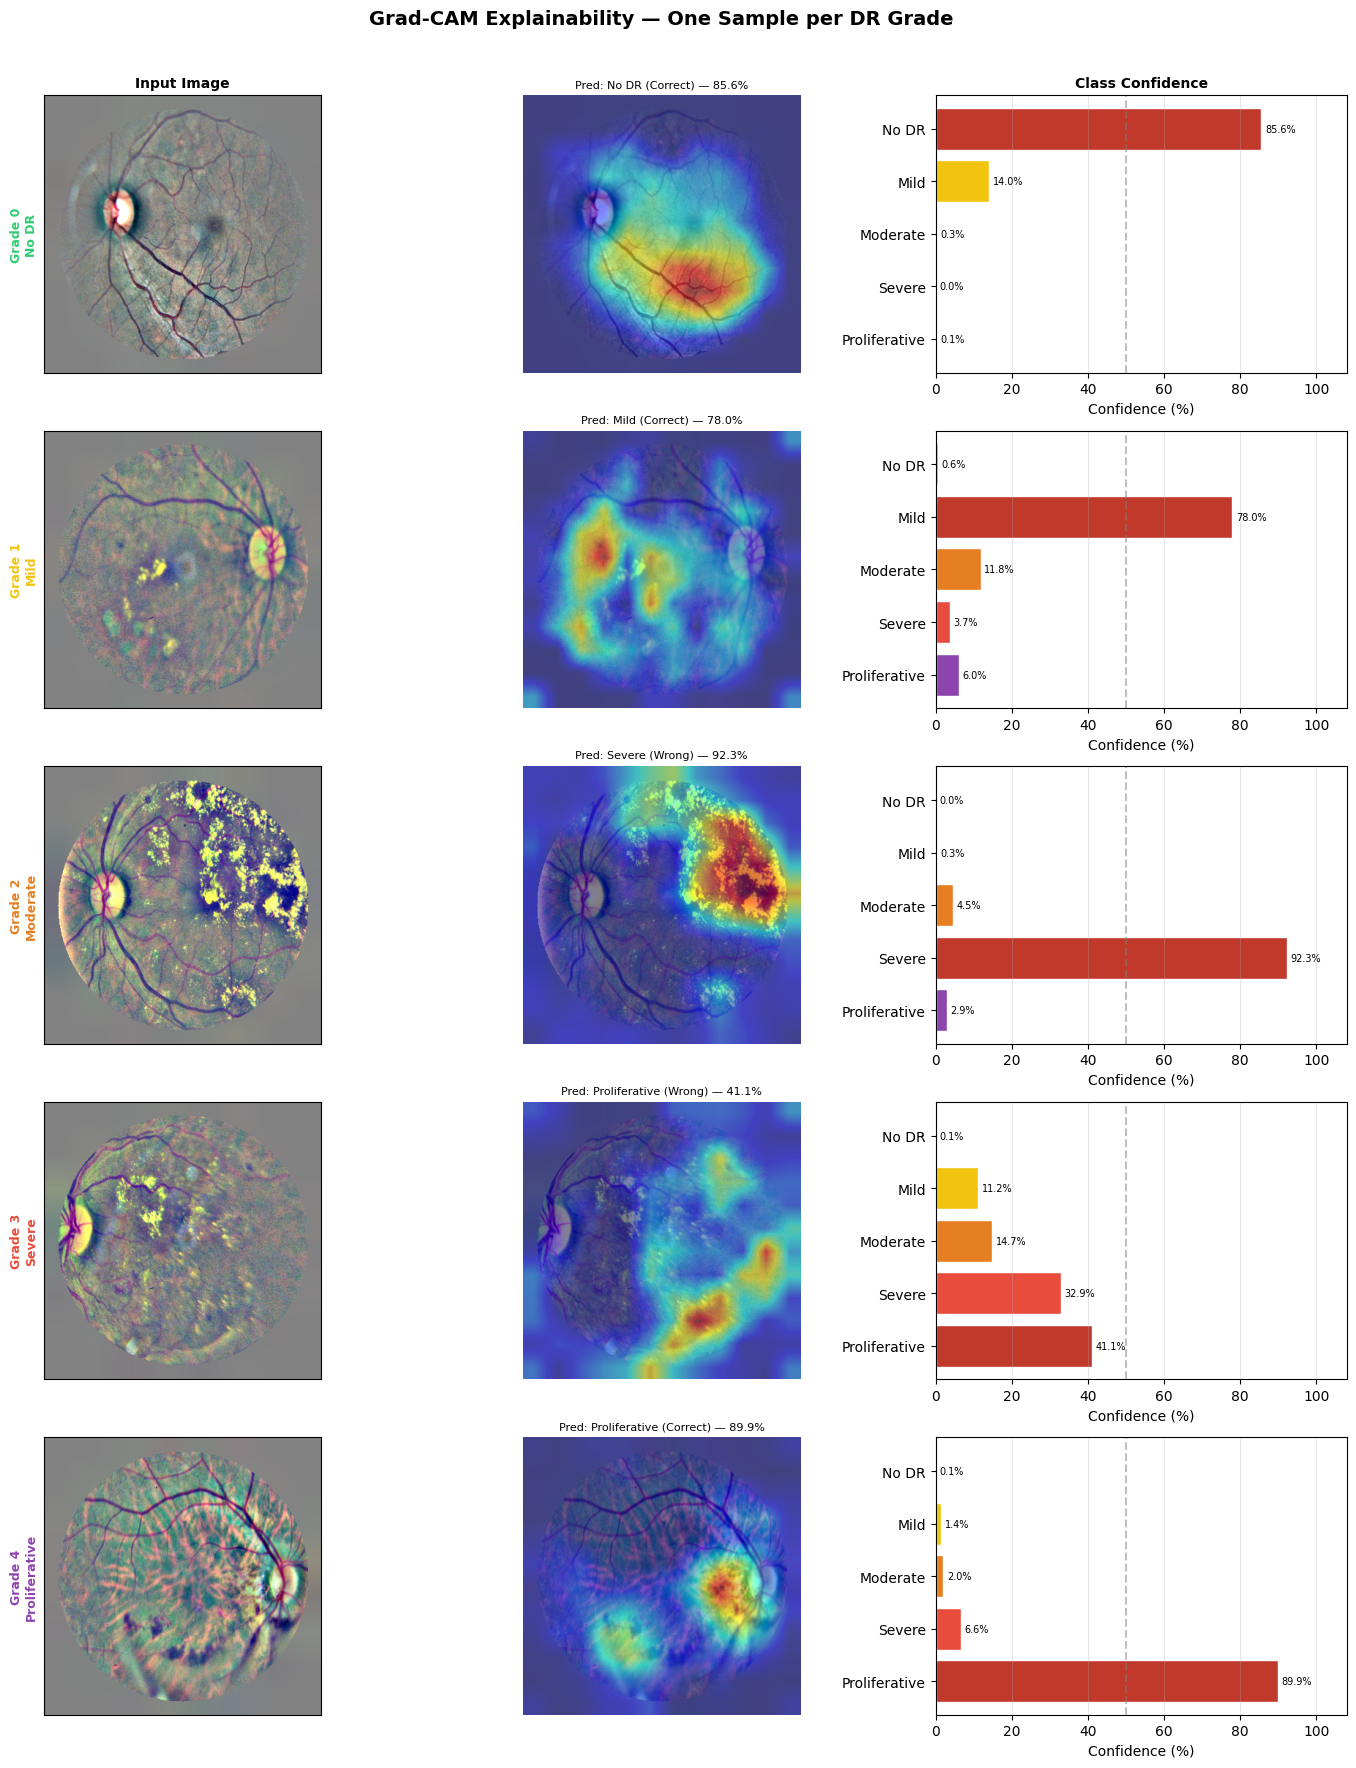

Grad-CAM visualisations saved


In [36]:
fig, axes = plt.subplots(NUM_CLASSES, 3, figsize=(14, 18))
fig.suptitle("Grad-CAM Explainability — One Sample per DR Grade",
             fontsize=14, fontweight="bold")

for ax, h in zip(axes[0], ["Input Image", "Grad-CAM Overlay", "Class Confidence"]):
    ax.set_title(h, fontsize=10, fontweight="bold")

for grade in range(NUM_CLASSES):
    subset = test_df[test_df["label"] == grade]
    if subset.empty:
        for ax in axes[grade]: ax.axis("off")
        continue

    path = subset.sample(1, random_state=SEED + grade).iloc[0]["filepath"]
    if not Path(path).exists():
        for ax in axes[grade]: ax.text(0.5,0.5,"Not found",ha="center"); ax.axis("off")
        continue

    cam_img, pred, probs = generate_gradcam(model, path)
    raw_img = load_and_preprocess(path)

    axes[grade][0].imshow(raw_img)
    axes[grade][0].set_ylabel(f"Grade {grade}\n{CLASS_NAMES[grade]}",
                              fontsize=9, fontweight="bold", color=PALETTE[grade])
    axes[grade][0].set_xticks([]); axes[grade][0].set_yticks([])

    tick = "Correct" if pred == grade else "Wrong"
    axes[grade][1].imshow(cam_img)
    axes[grade][1].set_title(f"Pred: {CLASS_NAMES[pred]} ({tick}) — {probs[pred]*100:.1f}%",
                             fontsize=8)
    axes[grade][1].axis("off")

    colors = list(PALETTE); colors[pred] = "#c0392b"
    bars = axes[grade][2].barh(CLASS_NAMES, probs * 100, color=colors, edgecolor="white")
    axes[grade][2].set_xlim(0, 108); axes[grade][2].set_xlabel("Confidence (%)")
    axes[grade][2].axvline(50, color="grey", ls="--", alpha=0.5)
    for bar, p in zip(bars, probs):
        axes[grade][2].text(bar.get_width()+1, bar.get_y()+bar.get_height()/2,
                            f"{p*100:.1f}%", va="center", fontsize=7)
    axes[grade][2].invert_yaxis(); axes[grade][2].grid(axis="x", alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(LOG_DIR / "gradcam_examples.png", dpi=120, bbox_inches="tight")
plt.show()
print("Grad-CAM visualisations saved")

---
# Phase 4: Monitoring Backend
<a id='phase4'></a>

Lightweight patient monitoring system:
- **SQLite database** — stores patient records and multi-visit scan predictions
- **Inference pipeline** — full preprocessing → prediction → Grad-CAM → clinical advice
- **Progression visualisation** — DR severity trend over multiple visits

## 4.1 Database Schema

In [37]:
def init_database(db_path=str(DB_PATH)):
    conn = sqlite3.connect(db_path)
    conn.executescript('''
        CREATE TABLE IF NOT EXISTS patients (
            patient_id    TEXT PRIMARY KEY,
            name          TEXT,
            age           INTEGER,
            gender        TEXT,
            diabetes_type TEXT,
            created_at    TEXT DEFAULT (datetime(\'now\'))
        );
        CREATE TABLE IF NOT EXISTS scans (
            scan_id         INTEGER PRIMARY KEY AUTOINCREMENT,
            patient_id      TEXT    NOT NULL,
            scan_date       TEXT    NOT NULL,
            image_path      TEXT,
            predicted_grade INTEGER NOT NULL,
            predicted_label TEXT    NOT NULL,
            confidence      REAL    NOT NULL,
            conf_no_dr      REAL,
            conf_mild       REAL,
            conf_moderate   REAL,
            conf_severe     REAL,
            conf_pdr        REAL,
            notes           TEXT,
            created_at      TEXT    DEFAULT (datetime(\'now\')),
            FOREIGN KEY (patient_id) REFERENCES patients(patient_id)
        );
        CREATE INDEX IF NOT EXISTS idx_scans_patient ON scans(patient_id, scan_date);
    ''')
    conn.commit()
    return conn


conn   = init_database()
tables = [t[0] for t in conn.execute("SELECT name FROM sqlite_master WHERE type='table'").fetchall()]
print(f"Monitoring DB: {DB_PATH}")
print(f"Tables: {tables}")

Monitoring DB: monitoring.db
Tables: ['patients', 'scans', 'sqlite_sequence']


## 4.2 Inference Pipeline Class

In [38]:
class DRInferencePipeline:
    RISK = {
        0: ("Low",      "GREEN",    "No apparent DR. Routine annual screening recommended."),
        1: ("Low",      "YELLOW",   "Mild NPDR. Follow-up in 12 months."),
        2: ("Moderate", "ORANGE",   "Moderate NPDR. Ophthalmology referral within 6 months."),
        3: ("High",     "RED",      "Severe NPDR. Urgent ophthalmology referral within 1 month."),
        4: ("Critical", "CRITICAL", "Proliferative DR. IMMEDIATE ophthalmology referral."),
    }

    def __init__(self, model, db_conn, device=DEVICE):
        self.model = model; self.conn = db_conn; self.device = device
        self.model.eval()

    def predict(self, image_path, generate_cam=True):
        img    = load_and_preprocess(image_path)
        tensor = val_transforms(image=img)["image"].unsqueeze(0).to(self.device)
        with torch.no_grad():
            probs = torch.softmax(self.model(tensor), 1).squeeze().cpu().numpy()
        grade           = int(probs.argmax())
        risk, icon, adv = self.RISK[grade]
        result          = {"grade": grade, "label": CLASS_NAMES[grade],
                           "confidence": float(probs[grade]), "all_probs": probs.tolist(),
                           "risk": risk, "icon": icon, "advice": adv, "cam_image": None}
        if generate_cam:
            result["cam_image"], _, _ = generate_gradcam(self.model, image_path)
        return result

    def add_patient(self, patient_id, name, age, gender, diabetes_type="Type 2"):
        try:
            self.conn.execute(
                "INSERT INTO patients (patient_id,name,age,gender,diabetes_type) VALUES (?,?,?,?,?)",
                (patient_id, name, age, gender, diabetes_type))
            self.conn.commit()
            print(f"Patient registered: {name} ({patient_id})")
        except sqlite3.IntegrityError:
            print(f"Patient {patient_id} already exists")

    def save_scan(self, patient_id, image_path, prediction, scan_date=None, notes=""):
        if scan_date is None: scan_date = datetime.date.today().isoformat()
        p = prediction["all_probs"]
        self.conn.execute(
            "INSERT INTO scans (patient_id,scan_date,image_path,predicted_grade,predicted_label,"
            "confidence,conf_no_dr,conf_mild,conf_moderate,conf_severe,conf_pdr,notes) "
            "VALUES (?,?,?,?,?,?,?,?,?,?,?,?)",
            (patient_id, scan_date, str(image_path), prediction["grade"], prediction["label"],
             prediction["confidence"], p[0], p[1], p[2], p[3], p[4], notes))
        self.conn.commit()
        return self.conn.execute("SELECT last_insert_rowid()").fetchone()[0]

    def get_patient_history(self, patient_id):
        return pd.read_sql_query(
            "SELECT scan_date,predicted_grade,predicted_label,confidence,"
            "conf_no_dr,conf_mild,conf_moderate,conf_severe,conf_pdr,notes "
            "FROM scans WHERE patient_id=? ORDER BY scan_date ASC",
            self.conn, params=(patient_id,))


pipeline = DRInferencePipeline(model=model, db_conn=conn)
print("Inference pipeline ready")

Inference pipeline ready


## 4.3 Demo: Simulate Multi-Visit Monitoring

In [39]:
DEMO_PATIENTS = [
    {"patient_id":"P001","name":"Arjun Sharma","age":54,"gender":"M","diabetes_type":"Type 2"},
    {"patient_id":"P002","name":"Priya Nair",  "age":48,"gender":"F","diabetes_type":"Type 1"},
]
for p in DEMO_PATIENTS:
    pipeline.add_patient(**p)

base_date = datetime.date(2022, 1, 15)

for patient in DEMO_PATIENTS:
    pid = patient["patient_id"]
    print(f"\nVisits for {patient['name']} ({pid}):")
    for visit in range(6):
        scan_date = (base_date + datetime.timedelta(days=visit*180)).isoformat()
        row       = test_df.sample(1, random_state=SEED + visit + ord(pid[1])).iloc[0]
        path      = row["filepath"]
        if not Path(path).exists():
            print(f"  Visit {visit+1}: image not found"); continue

        pred = pipeline.predict(path, generate_cam=False)
        pipeline.save_scan(pid, path, pred, scan_date, notes=f"Visit {visit+1} demo")
        print(f"  Visit {visit+1} ({scan_date}): [{pred['icon']}] "
              f"Grade {pred['grade']} — {pred['label']} ({pred['confidence']*100:.1f}%)")

print("\nDemo patient history populated")

Patient registered: Arjun Sharma (P001)
Patient registered: Priya Nair (P002)

Visits for Arjun Sharma (P001):
  Visit 1 (2022-01-15): [GREEN] Grade 0 — No DR (34.3%)
  Visit 2 (2022-07-14): [GREEN] Grade 0 — No DR (95.7%)
  Visit 3 (2023-01-10): [GREEN] Grade 0 — No DR (90.0%)
  Visit 4 (2023-07-09): [ORANGE] Grade 2 — Moderate (43.6%)
  Visit 5 (2024-01-05): [CRITICAL] Grade 4 — Proliferative (37.9%)
  Visit 6 (2024-07-03): [RED] Grade 3 — Severe (81.1%)

Visits for Priya Nair (P002):
  Visit 1 (2022-01-15): [GREEN] Grade 0 — No DR (34.3%)
  Visit 2 (2022-07-14): [GREEN] Grade 0 — No DR (95.7%)
  Visit 3 (2023-01-10): [GREEN] Grade 0 — No DR (90.0%)
  Visit 4 (2023-07-09): [ORANGE] Grade 2 — Moderate (43.6%)
  Visit 5 (2024-01-05): [CRITICAL] Grade 4 — Proliferative (37.9%)
  Visit 6 (2024-07-03): [RED] Grade 3 — Severe (81.1%)

Demo patient history populated


## 4.4 DR Progression Visualisation

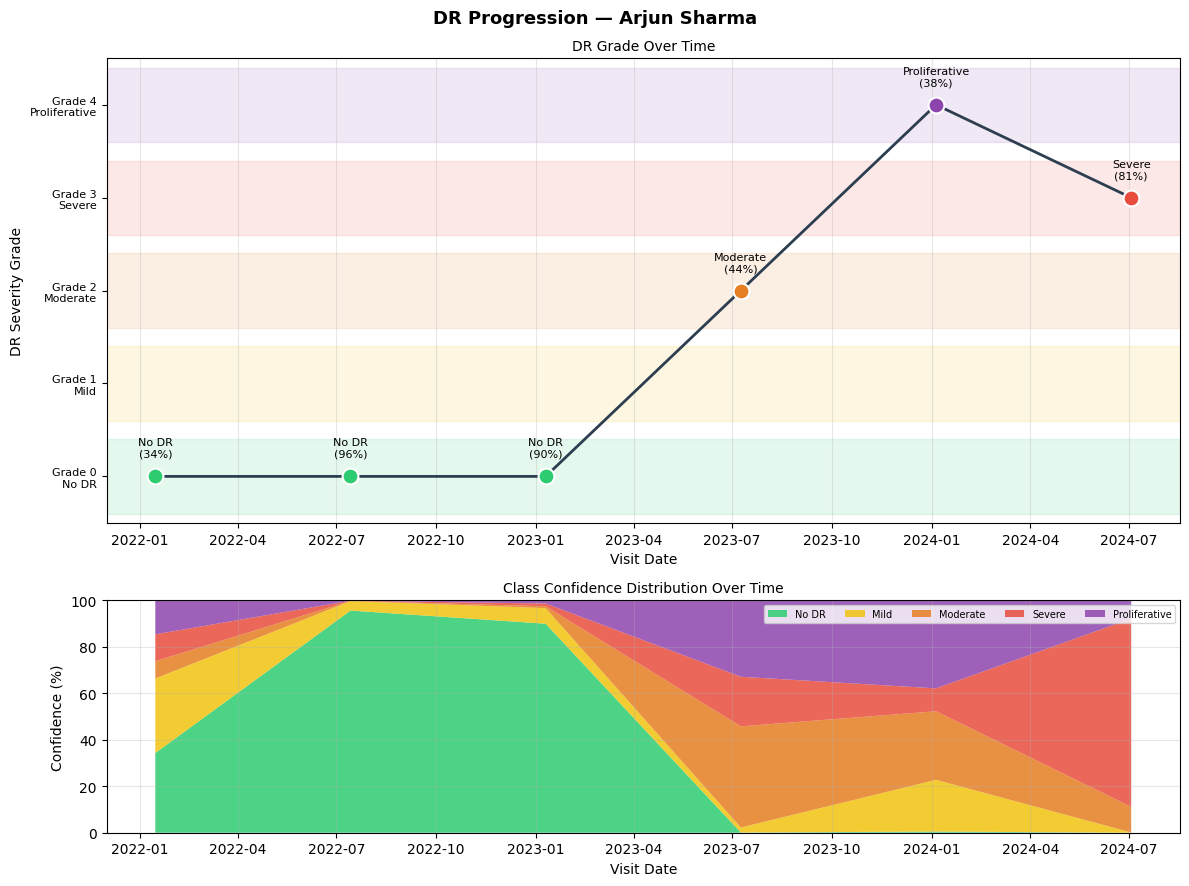

Saved: logs/progression_P001.png


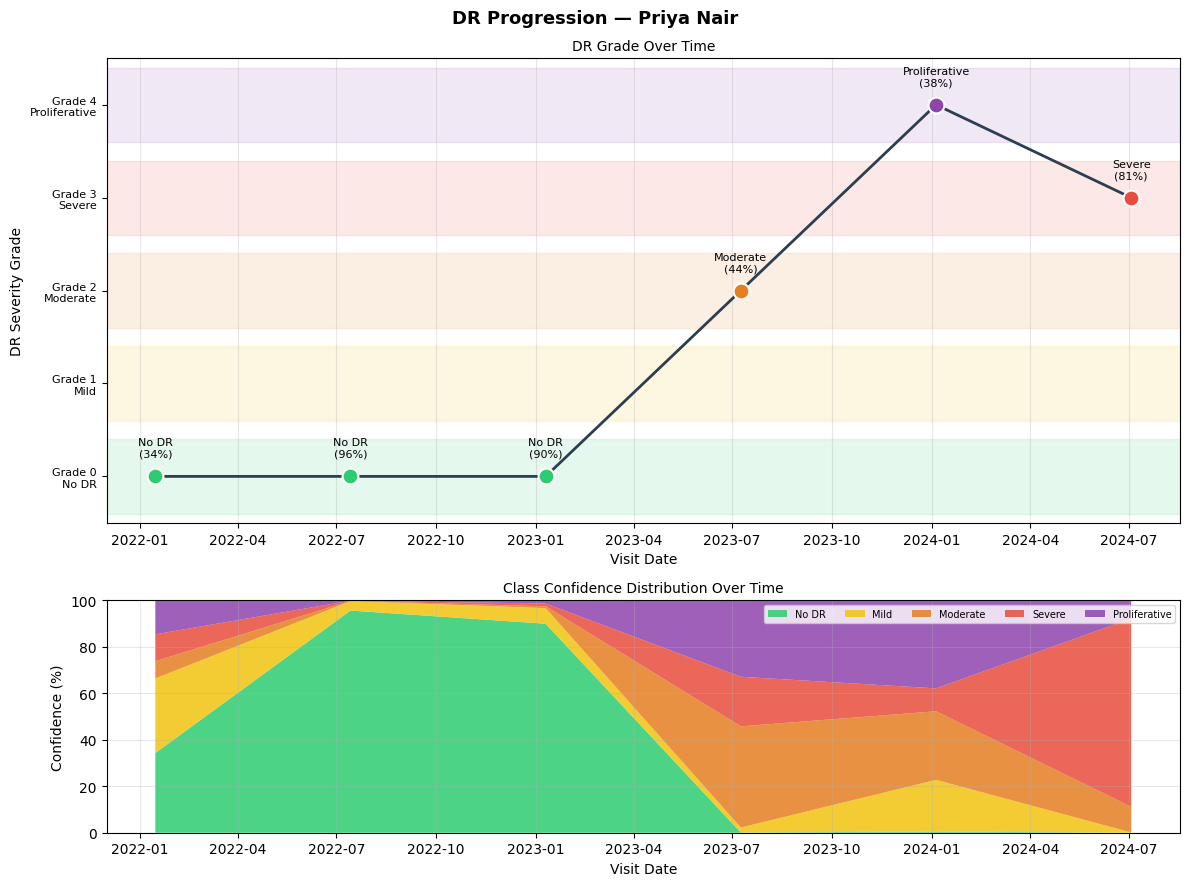

Saved: logs/progression_P002.png


In [40]:
def plot_progression(pipeline, patient_id, patient_name=None):
    df = pipeline.get_patient_history(patient_id)
    if df.empty: print(f"No records for {patient_id}"); return

    df["scan_date"] = pd.to_datetime(df["scan_date"])

    fig, axes = plt.subplots(2, 1, figsize=(12, 9), gridspec_kw={"height_ratios":[2,1]})
    fig.suptitle(f"DR Progression — {patient_name or patient_id}",
                 fontsize=13, fontweight="bold")

    # Grade over time
    ax = axes[0]
    for grade, color in enumerate(PALETTE):
        ax.axhspan(grade-0.4, grade+0.4, alpha=0.12, color=color, zorder=0)

    ax.plot(df["scan_date"], df["predicted_grade"], "o-",
            color="#2c3e50", lw=2, ms=9, zorder=3)
    for _, row in df.iterrows():
        ax.scatter(row["scan_date"], row["predicted_grade"],
                   color=PALETTE[int(row["predicted_grade"])],
                   s=130, zorder=4, edgecolors="white", linewidths=1.5)
        ax.annotate(f"{row['predicted_label']}\n({row['confidence']*100:.0f}%)",
                    (row["scan_date"], row["predicted_grade"]),
                    textcoords="offset points", xytext=(0, 14),
                    ha="center", fontsize=8)

    ax.set_yticks(range(NUM_CLASSES))
    ax.set_yticklabels([f"Grade {i}\n{CLASS_NAMES[i]}" for i in range(NUM_CLASSES)], fontsize=8)
    ax.set_ylim(-0.5, NUM_CLASSES - 0.5)
    ax.set_xlabel("Visit Date"); ax.set_ylabel("DR Severity Grade")
    ax.set_title("DR Grade Over Time", fontsize=10); ax.grid(axis="x", alpha=0.3)

    # Stacked confidence
    ax2   = axes[1]
    cols  = ["conf_no_dr","conf_mild","conf_moderate","conf_severe","conf_pdr"]
    conf  = df[cols].values.T * 100
    dates = df["scan_date"].values

    ax2.stackplot(dates, conf, labels=CLASS_NAMES, colors=PALETTE, alpha=0.85)
    ax2.set_ylim(0, 100)
    ax2.set_xlabel("Visit Date"); ax2.set_ylabel("Confidence (%)")
    ax2.set_title("Class Confidence Distribution Over Time", fontsize=10)
    ax2.legend(loc="upper right", fontsize=7, ncol=5); ax2.grid(alpha=0.3)

    plt.tight_layout()
    out = LOG_DIR / f"progression_{patient_id}.png"
    plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {out}")


for p in DEMO_PATIENTS:
    plot_progression(pipeline, p["patient_id"], p["name"])

## 4.5 Single-Image Inference Demo

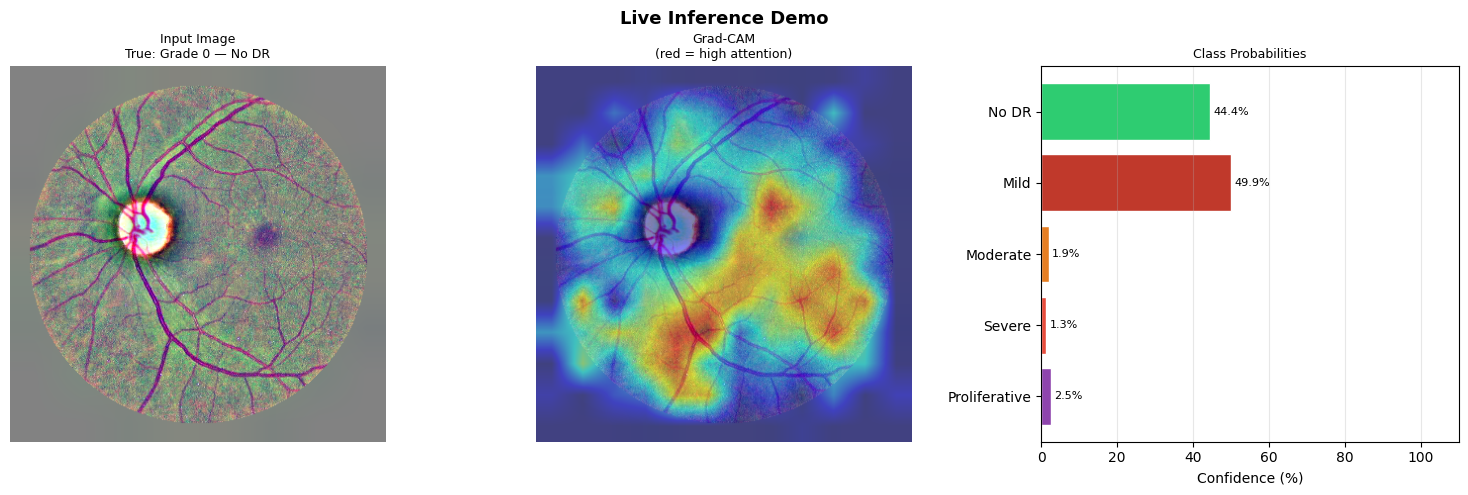


  DIAGNOSIS REPORT
  Predicted Grade : 1 — Mild
  Confidence      : 49.9%
  Risk Level      : [YELLOW] Low
  Clinical Advice : Mild NPDR. Follow-up in 12 months.
  True Grade      : 0 — No DR

DISCLAIMER: Proof-of-concept only. NOT for clinical use.
Always consult a qualified ophthalmologist.


In [41]:
# Replace demo_path with any new fundus image for live inference
demo_row   = test_df.sample(1, random_state=999).iloc[0]
demo_path  = demo_row["filepath"]
true_grade = demo_row["label"]

if Path(demo_path).exists():
    result = pipeline.predict(demo_path, generate_cam=True)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle("Live Inference Demo", fontsize=13, fontweight="bold")

    raw = load_and_preprocess(demo_path)
    axes[0].imshow(raw)
    axes[0].set_title(f"Input Image\nTrue: Grade {true_grade} — {CLASS_NAMES[true_grade]}",
                      fontsize=9)
    axes[0].axis("off")

    if result["cam_image"] is not None:
        axes[1].imshow(result["cam_image"])
        axes[1].set_title("Grad-CAM\n(red = high attention)", fontsize=9)
        axes[1].axis("off")

    probs  = result["all_probs"]
    colors = list(PALETTE); colors[result["grade"]] = "#c0392b"
    bars   = axes[2].barh(CLASS_NAMES, [p*100 for p in probs],
                          color=colors, edgecolor="white")
    axes[2].set_xlim(0, 110); axes[2].set_xlabel("Confidence (%)")
    axes[2].set_title("Class Probabilities", fontsize=9)
    for bar, p in zip(bars, probs):
        axes[2].text(bar.get_width()+1, bar.get_y()+bar.get_height()/2,
                     f"{p*100:.1f}%", va="center", fontsize=8)
    axes[2].invert_yaxis(); axes[2].grid(axis="x", alpha=0.3)

    plt.tight_layout()
    plt.savefig(LOG_DIR / "inference_demo.png", dpi=150, bbox_inches="tight")
    plt.show()

    print("\n" + "="*55)
    print("  DIAGNOSIS REPORT")
    print("="*55)
    print(f"  Predicted Grade : {result['grade']} — {result['label']}")
    print(f"  Confidence      : {result['confidence']*100:.1f}%")
    print(f"  Risk Level      : [{result['icon']}] {result['risk']}")
    print(f"  Clinical Advice : {result['advice']}")
    print(f"  True Grade      : {true_grade} — {CLASS_NAMES[true_grade]}")
    print("="*55)
    print("\nDISCLAIMER: Proof-of-concept only. NOT for clinical use.")
    print("Always consult a qualified ophthalmologist.")
else:
    print("Run after downloading the dataset.")

## 4.6 Export Model for Production Deployment

In [43]:
# 1. PyTorch state dict (most portable)
export_path = CKPT_DIR / "dr_efficientnet_b4_final.pth"
torch.save({
    "model_state_dict": model.state_dict(),
    "model_config": {"architecture": "tf_efficientnet_b4_ns",
                     "num_classes": NUM_CLASSES, "img_size": IMG_SIZE,
                     "class_names": CLASS_NAMES},
    "metrics": {"val_qwk": best_kappa, "test_qwk": test_kappa, "test_acc": test_acc},
    "preprocessing": {"imagenet_mean": IMAGENET_MEAN, "imagenet_std": IMAGENET_STD},
}, export_path)
print(f"State dict  saved: {export_path}")

# 2. TorchScript (C++ / mobile)
model.eval()
dummy      = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
scripted   = torch.jit.trace(model, dummy)
script_path = CKPT_DIR / "dr_model_scripted.pt"
scripted.save(str(script_path))
print(f"TorchScript saved: {script_path}")

# 3. ONNX (TensorRT / OpenVINO / CoreML)
onnx_path = CKPT_DIR / "dr_model.onnx"
torch.onnx.export(
    model, dummy, str(onnx_path),
    input_names=["fundus_image"], output_names=["dr_logits"],
    dynamic_axes={"fundus_image": {0:"batch"}, "dr_logits": {0:"batch"}},
    opset_version=17)
print(f"ONNX        saved: {onnx_path}")

print("\nAll exported files:")
for f in sorted(CKPT_DIR.iterdir()):
    print(f"  {f.name:<45} {f.stat().st_size/1e6:.1f} MB")

State dict  saved: checkpoints/dr_efficientnet_b4_final.pth
TorchScript saved: checkpoints/dr_model_scripted.pt
ONNX        saved: checkpoints/dr_model.onnx

All exported files:
  best_model.pth                                222.7 MB
  dr_efficientnet_b4_final.pth                  74.7 MB
  dr_model.onnx                                 73.9 MB
  dr_model_scripted.pt                          75.8 MB
  model_epoch_3.pth                             74.6 MB
  phase1_complete.pth                           74.6 MB


---
# Project Summary
<a id='summary'></a>

## Results

| Metric | Value |
|--------|-------|
| Architecture | EfficientNet-B4 (NoisyStudent) |
| Input resolution | 380 × 380 px |
| Dataset | APTOS 2019 (~3,600 images) |
| Train / Val / Test split | 70% / 15% / 15% (stratified) |
| Loss function | Focal Loss (γ=2) + inverse-frequency class weights |
| Augmentation | Flip · Rotate · Brightness/Contrast · GaussNoise · CoarseDropout |
| Preprocessing | Ben Graham crop + CLAHE |
| Primary metric | **Quadratic Weighted Kappa (QWK)** |
| Best Val QWK | *(run all cells to populate)* |
| Test QWK | *(run all cells to populate)* |

## Key Design Decisions

1. **Quadratic Weighted Kappa** as primary metric — DR grading is ordinal; penalises large errors more, matches clinical severity
2. **EfficientNet-B4 NoisyStudent** — stronger domain-shift robustness vs standard ImageNet weights; ideal for medical imagery  
3. **Two-phase fine-tuning** — stable convergence via frozen backbone warmup before full fine-tuning  
4. **Focal Loss + WeightedRandomSampler** — dual imbalance strategy; sampler balances batches, loss focuses on hard minority examples  
5. **Ben Graham preprocessing** — local mean subtraction normalises uneven fundus illumination  
6. **Grad-CAM** — clinical credibility; proves model attends to pathological structures

## Limitations

- ~3,600 images is small for medical AI — may not generalise across camera types, ethnicities, or imaging conditions  
- Single-dataset evaluation — external validation on EyePACS / Messidor-2 needed before deployment  
- No clinical context (HbA1c, diabetes duration) — these are strong DR progression predictors  
- Proof-of-concept: **NOT for clinical deployment** without regulatory review and prospective validation

## Future Work

- Federated learning across hospital sites (HIPAA/GDPR privacy compliance)  
- Larger, more diverse datasets (EyePACS 88k, Messidor-2, DDR)  
- Multi-task learning: DR grading + lesion segmentation (U-Net branch)  
- Uncertainty quantification (MC Dropout, Deep Ensembles)  
- Longitudinal model incorporating time-series scan data  
- Streamlit / FastAPI web dashboard for clinical demo

---

> ⚠️ **Clinical Disclaimer**: This is a research proof-of-concept for academic purposes only.  
> It has NOT undergone clinical validation and must NOT be used for diagnosis or treatment.  
> Always consult a qualified ophthalmologist for retinal evaluation.